<a href="https://colab.research.google.com/github/AfraazUlHaque/data-analytics/blob/main/knn(without_library).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00236/seeds_dataset.txt"

df = pd.read_csv(url, sep=r"\s+", header=None)

X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

np.random.seed(42)

indices = np.random.permutation(len(X))

X = X[indices]
y = y[indices]

split = int(0.8 * len(X))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

class KNN:

    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, X):
        predictions = []

        for sample in X:

            distances = np.sqrt(
                np.sum((self.X_train - sample) ** 2, axis=1)
            )

            nearest = np.argsort(distances)[:self.k]

            labels = self.y_train[nearest]

            unique, counts = np.unique(
                labels, return_counts=True
            )

            predictions.append(unique[np.argmax(counts)])

        return np.array(predictions)


model = KNN(k=5)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = np.mean(y_pred == y_test)

print("Actual:", y_test)
print("Predicted:", y_pred)
print("Accuracy:", accuracy * 100, "%")


Actual: [3 2 3 3 1 1 2 1 3 3 3 1 1 2 1 1 3 3 2 1 3 3 1 1 3 2 3 2 2 2 2 2 2 3 1 3 2
 2 1 2 3 2]
Predicted: [3 2 3 3 3 1 2 1 3 3 3 1 1 2 1 1 3 3 2 2 3 3 1 1 3 2 3 2 2 2 2 2 2 3 1 3 2
 2 1 2 1 2]
Accuracy: 92.85714285714286 %


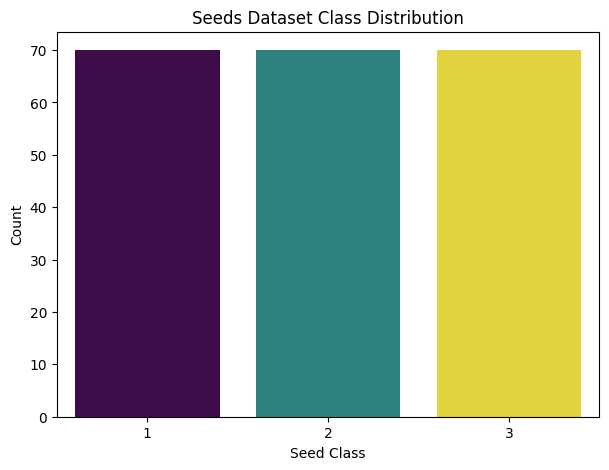

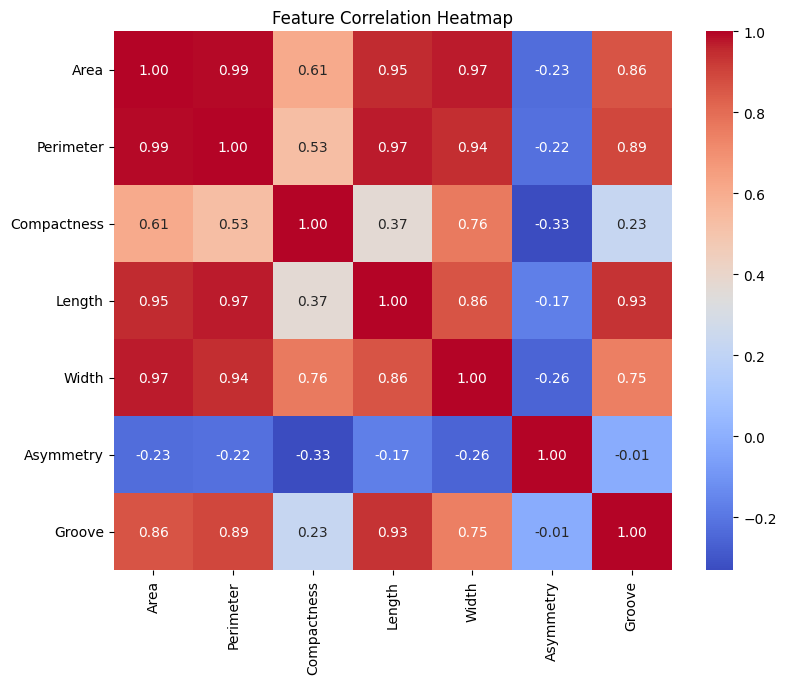

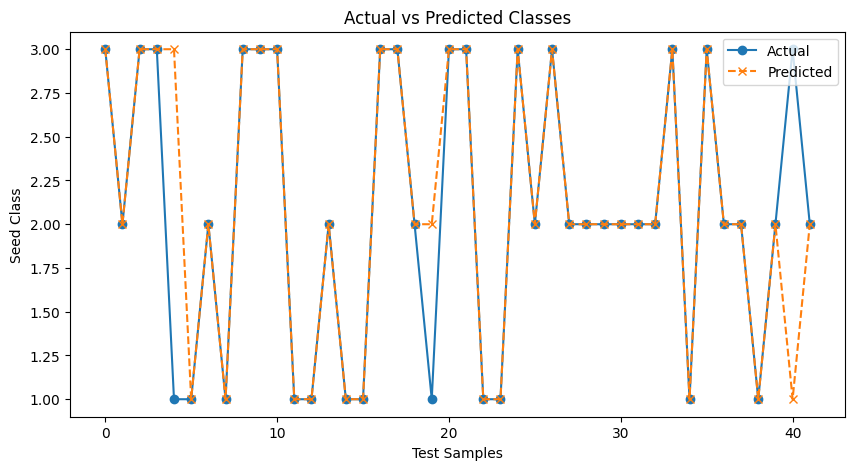

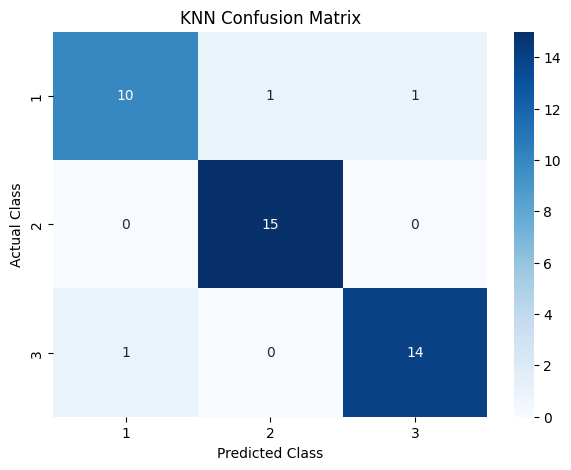

In [2]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(7, 5))
sns.countplot(x=y, hue=y, palette="viridis", legend=False)
plt.title("Seeds Dataset Class Distribution")
plt.xlabel("Seed Class")
plt.ylabel("Count")
plt.show()


plt.figure(figsize=(9, 7))
sns.heatmap(
    pd.DataFrame(X, columns=[
        "Area", "Perimeter", "Compactness",
        "Length", "Width", "Asymmetry", "Groove"
    ]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.show()


plt.figure(figsize=(10, 5))
plt.plot(y_test, "o-", label="Actual", markersize=6)
plt.plot(y_pred, "x--", label="Predicted", markersize=6)
plt.title("Actual vs Predicted Classes")
plt.xlabel("Test Samples")
plt.ylabel("Seed Class")
plt.legend()
plt.show()


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.unique(y),
    yticklabels=np.unique(y)
)
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()
